# 16 Groundwater head beside the Tule Pond section

```
Author: Danielle Lindsay
Environment: opera_disp_feb13. Run time: about a minute (reading the PDFs).
```

**What this notebook does.** The rise in groundwater head in the aquifers beside the Tule Pond section from the fall
of one year to the spring of the next (the winter recharge, when the SSEs begin), and its size as a pore-pressure
change, from the **public** annual Groundwater Monitoring Reports (GWMR) of the Alameda County Water District (ACWD)
only (SM M9; main-text discussion). Not part of the v1.0.0 release.

1. **The reports** (section 2). The Spring and Fall Groundwater Monitoring Records appendices of every report in
   `external_inputs/ACWD_GWMR_archive` (water years 2015, 2017-2023, 2025; 2016 and 2024 were not found), parsed from
   the PDFs as published (`groundwater_utils.py`, SHA256 checked). The number of table rows is checked against each
   report's Table 1.
2. **The wells** (section 3). Every well in the reports within 2 km of our mapped trace whose nearest trace point lies
   along the SSE section (`04_creep_length_*`), placed at the centre of the 40-acre tract of its State Well Number
   (about +/-200 m). The side of the fault is the aquifer code: ACWD's AHF (Above Hayward Fault) aquifer lies east of
   the fault, all others west.
3. **The winter rise** (section 4). Spring level of water year Y minus the fall level of Y-1, for the six winters with
   consecutive reports (2017/18 to 2022/23). Levels flagged RUN (pump running) or without a level (e.g. UTM, unable to
   measure) are excluded; a rise larger than 15 m is dropped as a misread row. A head change $\Delta h$ is a
   pore-pressure change $\Delta p = \rho_w g \Delta h$ (9.80665 kPa per metre); the change in fault strength is
   $\mu' \Delta p$ at an effective friction $\mu'$ = 0.4 (Freed 2005). The SSE winters are those of the five InSAR
   onsets (notebook 04).
4. **Does the selection matter?** (section 5) The same numbers for wells within 1, 1.5, 2 and 3 km, the peak-slip zone
   only (`04_band90_*`), the section +/-1 km, the wells measured in all six winters, and the earlier choice of seven
   survey sections.
5. **Figure** (section 6): the wells, the rise per well and winter, and the winter medians with and without an SSE.

Nothing from `external_inputs/ACWD_water_well_data` (ACWD-supplied series, not public) is read.
The numbers go to the registry as `16_*` and the stats sidecar `16_groundwater_head_stats.txt`.

## 1. Imports and settings

In [1]:
import os
import re

import groundwater_utils as gw
import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import pygmt                                     # Figure

notebook = "16_groundwater_head"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
REG = utils.Registry(notebook, common_paths, repo_dir)

archive_dir = common_paths["acwd_gwmr_archive"]
profiles_file = common_paths["fault_profiles"]
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")   # the InSAR SSE onsets (04)

max_dist_km = 2.0                      # the rule: wells within 2 km of the trace
friction = 0.4                         # effective friction (Freed 2005), for the strength change
sensitivity_dist_km = (1.0, 1.5, 2.0, 3.0)
seven_sections = [21, 22, 27, 28, 29, 33, 34]   # T4S R1W sections the section crosses: the earlier selection (2025 draft)

# the SSE section and the peak-slip zone from notebook 04's registry rows
latest = REG.latest().set_index("key")
section_km = tuple(round(float(latest.loc[f"04_creep_length_{e}_km", "value"]), 1) for e in ("lo", "hi"))
peak_km = tuple(round(float(latest.loc[f"04_band90_{e}_km", "value"]), 1) for e in ("lo", "hi"))
print("SSE section", section_km, "km; peak-slip zone (90 % band)", peak_km, "km")

files = gw.report_files(archive_dir)        # water year -> PDF, each checked against SHA256SUMS.txt
REG.inputs(*files.values(), profiles_file, events_file)
for wy, f in files.items():
    print(wy, os.path.basename(f))

Registry for 16_groundwater_head: run 72673b26, git 5401649+
SSE section (56.3, 62.2) km; peak-slip zone (90 % band) (58.2, 59.8) km
2015 2015 GWMR.pdf
2017 2017 GWMR.pdf
2018 2018 GWMR.pdf
2019 2019 GWMR.pdf
2020 2020 GWMR.pdf
2021 2021 GWMR.pdf
2022 2022 GWMR.pdf
2023 2023 GWMR.pdf
2025 2025 GWMR.pdf


## 2. Parse every report

The two appendices of each report: their pages are found from the appendix title pages. Checks: one reading per well
per campaign; the number of table rows matches each report's Table 1 "total number of wells in the program" (given
2019-2025) to within two wells (2019 spring: 283 rows vs 285; 2025 spring: 295 vs 293; every State Well Number on the
appendix pages is parsed, so the difference is inside the report).

In [2]:
tables, check = {}, []
for wy, f in files.items():
    t, pages = gw.read_report(f)
    tables[wy] = t
    full = gw.pdf_text(f, 1, gw.n_pages(f))
    prog = re.search(r"TOTAL NUMBER OF WELLS IN THE PROGRAM\s+(\d+)\s+(\d+)", full)
    row = dict(water_year=wy, pages=f"{pages[0]}-{pages[1]}, {pages[2]}-{pages[3]}")
    for k, s in t.items():
        assert not s.well.duplicated().any(), (wy, k)          # one reading per well per campaign
        row[f"{k}_rows"] = len(s)
        row[f"{k}_levels"] = int(s.water_elevation_ft.map(gw.is_level).sum())
    row["table1_program"] = "/".join(prog.groups()) if prog else "not given"
    if prog:
        assert all(abs(a - int(b)) <= 2 for a, b in zip((row["spring_rows"], row["fall_rows"]), prog.groups())), wy
    check.append(row)
check = pd.DataFrame(check)
print(check.to_string(index=False))

 water_year        pages  spring_rows  spring_levels  fall_rows  fall_levels table1_program
       2015 53-59, 61-70          285            255        284          252      not given
       2017 63-69, 71-80          279            228        283          235      not given
       2018 63-69, 71-80          280            231        285          239      not given
       2019 66-72, 74-83          283            223        285          236        285/285
       2020 68-74, 76-85          283            220        289          221        283/289
       2021 68-74, 76-85          286            219        284          230        286/284
       2022 68-74, 76-85          294            246        296          254        294/296
       2023 66-72, 74-83          295            233        296          248        295/296
       2025 80-86, 88-96          295            242        295          243        293/295


## 3. The SSE winters and the trace

The water years of the five InSAR onsets (notebook 04; the water year runs from 1 October and is named by the year in
which it ends). The trace is our mapped trace with notebook 04's along-fault km.

In [3]:
events = pd.read_csv(events_file)
onsets = pd.to_datetime(events[events.segment == "TULEPOND"].onset_lo_utc)
sse_water_years = sorted(set(onsets.dt.year + (onsets.dt.month >= 10)))
assert len(sse_water_years) == len(onsets) == 5, "expected five InSAR SSEs, one per water year"
print("InSAR SSE water years:", sse_water_years)

trace = pd.read_csv(profiles_file)
trace["km"] = utils.lat_to_km_map(profiles_file)(trace.ft_lat.values)

InSAR SSE water years: [2017, 2019, 2021, 2023, 2025]


## 4. The winter rise beside the section

In [4]:
rises = gw.all_winter_rises(tables, trace.ft_lat, trace.ft_lon, trace.km, sse_water_years)
rises["in_7_sections"] = rises.well.str.startswith("4S/1W-") & rises.well.str[6:8].astype(int).isin(seven_sections)
R = gw.select_wells(rises, max_dist_km, section_km)
winters = sorted(R.winter.unique())
assert len(winters) == 6, winters
n_wells = R.well.nunique()
n_east, n_west = R[R.side == "east"].well.nunique(), R[R.side == "west"].well.nunique()
assert n_east + n_west == n_wells, "a well on both sides"
print(f"{n_wells} wells ({n_east} east, {n_west} west), {len(R)} well-winters, {R.well.str[:9].nunique()} tract positions, "
      f"winters {winters[0]} to {winters[-1]}")

per_winter = R.groupby(["winter", "side"]).agg(n=("rise_m", "size"), median_m=("rise_m", "median"),
                                              sse=("sse", "first")).unstack("side")
print(per_winter.round(2).to_string())

med_kpa = gw.winter_medians_kpa(R)
is_sse = med_kpa.index.isin(sse_water_years)
n_sse_winters, n_other_winters = int(is_sse.sum()), int((~is_sse).sum())
group = {}
for side in ("east", "west"):
    group[side] = {"sse_kpa": med_kpa.loc[is_sse, side].mean(), "non_kpa": med_kpa.loc[~is_sse, side].mean()}
    g = group[side]
    print(f"{side}: mean of the winter medians, SSE winters {g['sse_kpa']:.1f} kPa ({g['sse_kpa'] / gw.KPA_PER_M:.2f} m), "
          f"other winters {g['non_kpa']:.1f} kPa ({g['non_kpa'] / gw.KPA_PER_M:.2f} m)")
overlap = {side: (med_kpa.loc[is_sse, side].min() <= med_kpa.loc[~is_sse, side].max()) for side in ("east", "west")}
print("SSE and other winters overlap:", overlap)

q_m = np.percentile(R.rise_m, [25, 50, 75])
q_kpa = gw.pressure_kpa(q_m)
strength = gw.strength_change_kpa(q_kpa, friction)
smallest_west_wy = int(med_kpa.west.idxmin())
smallest_west_kpa = med_kpa.west.min()
print(f"all wells and winters: median {q_m[1]:.2f} m = {q_kpa[1]:.1f} kPa, IQR {q_m[0]:.2f}-{q_m[2]:.2f} m = "
      f"{q_kpa[0]:.1f}-{q_kpa[2]:.1f} kPa; strength change at mu' {friction}: {strength[1]:.1f} kPa "
      f"({strength[0]:.1f}-{strength[2]:.1f})")
print(f"smallest west-of-fault winter median: {smallest_west_wy - 1}/{str(smallest_west_wy)[2:]}, {smallest_west_kpa:.1f} kPa")
R.round(4).to_csv(os.path.join(out_dir, "winter_rise_by_well.csv"), index=False)

73 wells (24 east, 49 west), 385 well-winters, 34 tract positions, winters 2017/18 to 2022/23
           n      median_m          sse       
side    east west     east  west   east   west
winter                                        
2017/18   20   42    -0.10  1.06  False  False
2018/19   21   43     4.69  2.82   True   True
2019/20   20   44    -0.02  0.61  False  False
2020/21   18   46     1.21  0.28   True   True
2021/22   20   47     3.97  0.97  False  False
2022/23   21   43     5.05  3.35   True   True
east: mean of the winter medians, SSE winters 35.8 kPa (3.65 m), other winters 12.6 kPa (1.28 m)
west: mean of the winter medians, SSE winters 21.1 kPa (2.15 m), other winters 8.6 kPa (0.88 m)
SSE and other winters overlap: {'east': np.True_, 'west': np.True_}
all wells and winters: median 1.13 m = 11.1 kPa, IQR 0.48-2.98 m = 4.7-29.2 kPa; strength change at mu' 0.4: 4.4 kPa (1.9-11.7)
smallest west-of-fault winter median: 2020/21, 2.8 kPa


## 5. Does the well selection matter?

The numbers of section 4 for other selections. The text quotes the range over the distance rules (1 to 3 km).

In [5]:
def summarise(D, name):
    m = gw.winter_medians_kpa(D)
    s = m.index.isin(sse_water_years)
    q = gw.pressure_kpa(np.percentile(D.rise_m, [25, 50, 75]))
    return dict(selection=name, wells=D.well.nunique(), well_winters=len(D),
                sse_east_kpa=m.loc[s, "east"].mean(), sse_west_kpa=m.loc[s, "west"].mean(),
                non_east_kpa=m.loc[~s, "east"].mean(), non_west_kpa=m.loc[~s, "west"].mean(),
                median_kpa=q[1], iqr_lo_kpa=q[0], iqr_hi_kpa=q[2],
                smallest_west_winter=int(m.west.idxmin()), smallest_west_kpa=m.west.min())

lo, hi = section_km
n_winters = R.groupby("well").water_year.nunique()
rows = [summarise(gw.select_wells(rises, d, section_km), f"Within {d:g} km, beside the SSE section" +
                  (" (the rule)" if d == max_dist_km else "")) for d in sensitivity_dist_km]
rows += [summarise(gw.select_wells(rises, max_dist_km, peak_km), f"Within {max_dist_km:g} km, beside the peak-slip zone only"),
         summarise(gw.select_wells(rises, max_dist_km, (lo - 1, hi + 1)), f"Within {max_dist_km:g} km, SSE section +/-1 km along strike"),
         summarise(R[R.well.isin(n_winters[n_winters == len(winters)].index)], f"Within {max_dist_km:g} km, wells measured in all six winters"),
         summarise(rises[rises.in_7_sections], "Earlier selection: seven survey sections")]
sens = pd.DataFrame(rows)
sens.round(3).to_csv(os.path.join(out_dir, "well_selection_sensitivity.csv"), index=False)
pd.set_option("display.width", 220)
print(sens.round(1).to_string(index=False))
by_dist = sens.iloc[:len(sensitivity_dist_km)]
dist_lo, dist_hi = by_dist.median_kpa.min(), by_dist.median_kpa.max()
print(f"median over the distance rules {sensitivity_dist_km[0]:g}-{sensitivity_dist_km[-1]:g} km: {dist_lo:.1f}-{dist_hi:.1f} kPa; "
      f"over all selections {sens.median_kpa.min():.1f}-{sens.median_kpa.max():.1f} kPa")
assert (sens.sse_east_kpa > sens.non_east_kpa).all() and (sens.sse_west_kpa > sens.non_west_kpa).all()

                                     selection  wells  well_winters  sse_east_kpa  sse_west_kpa  non_east_kpa  non_west_kpa  median_kpa  iqr_lo_kpa  iqr_hi_kpa  smallest_west_winter  smallest_west_kpa
           Within 1 km, beside the SSE section     57           296          36.4          21.5          12.5           8.9        12.3         5.5        33.1                  2021                3.9
         Within 1.5 km, beside the SSE section     67           349          36.0          21.0          12.8           8.6        11.3         5.0        29.4                  2021                2.7
Within 2 km, beside the SSE section (the rule)     73           385          35.8          21.1          12.6           8.6        11.1         4.7        29.2                  2021                2.8
           Within 3 km, beside the SSE section     91           482          35.5          20.9          12.4           8.1        10.4         4.5        28.4                  2021               

## 6. Figure: the winter rise beside the section

pygmt, 19 cm wide, Helvetica 8.5-10 pt. A: the wells on our mapped trace (SSE section black; dashed: 2 km of the
section), map rotated with the fault up the page; wells sharing a tract are fanned out with leader lines to the tract
centre (black dot), kept on their own side of the trace; colour = each well's median rise. B: the rise per well and
winter, median and interquartile range per side, SSE winters gray, pooled median dashed. C: the winter medians without
and with an SSE, bar = mean.

73 wells at 34 tract positions; 53 symbols offset from their tract
panel widths: A 3.74, B 7.83, C 3.74 cm; height 5.5 cm


Saved figure to: /private/tmp/claude-502/-Users-dlindsay/0fdd737d-78e2-4e46-9e93-b9a364351a33/scratchpad/nb16_root/Figures_2026-11-25/figS_groundwater_winter_rise_2km.png


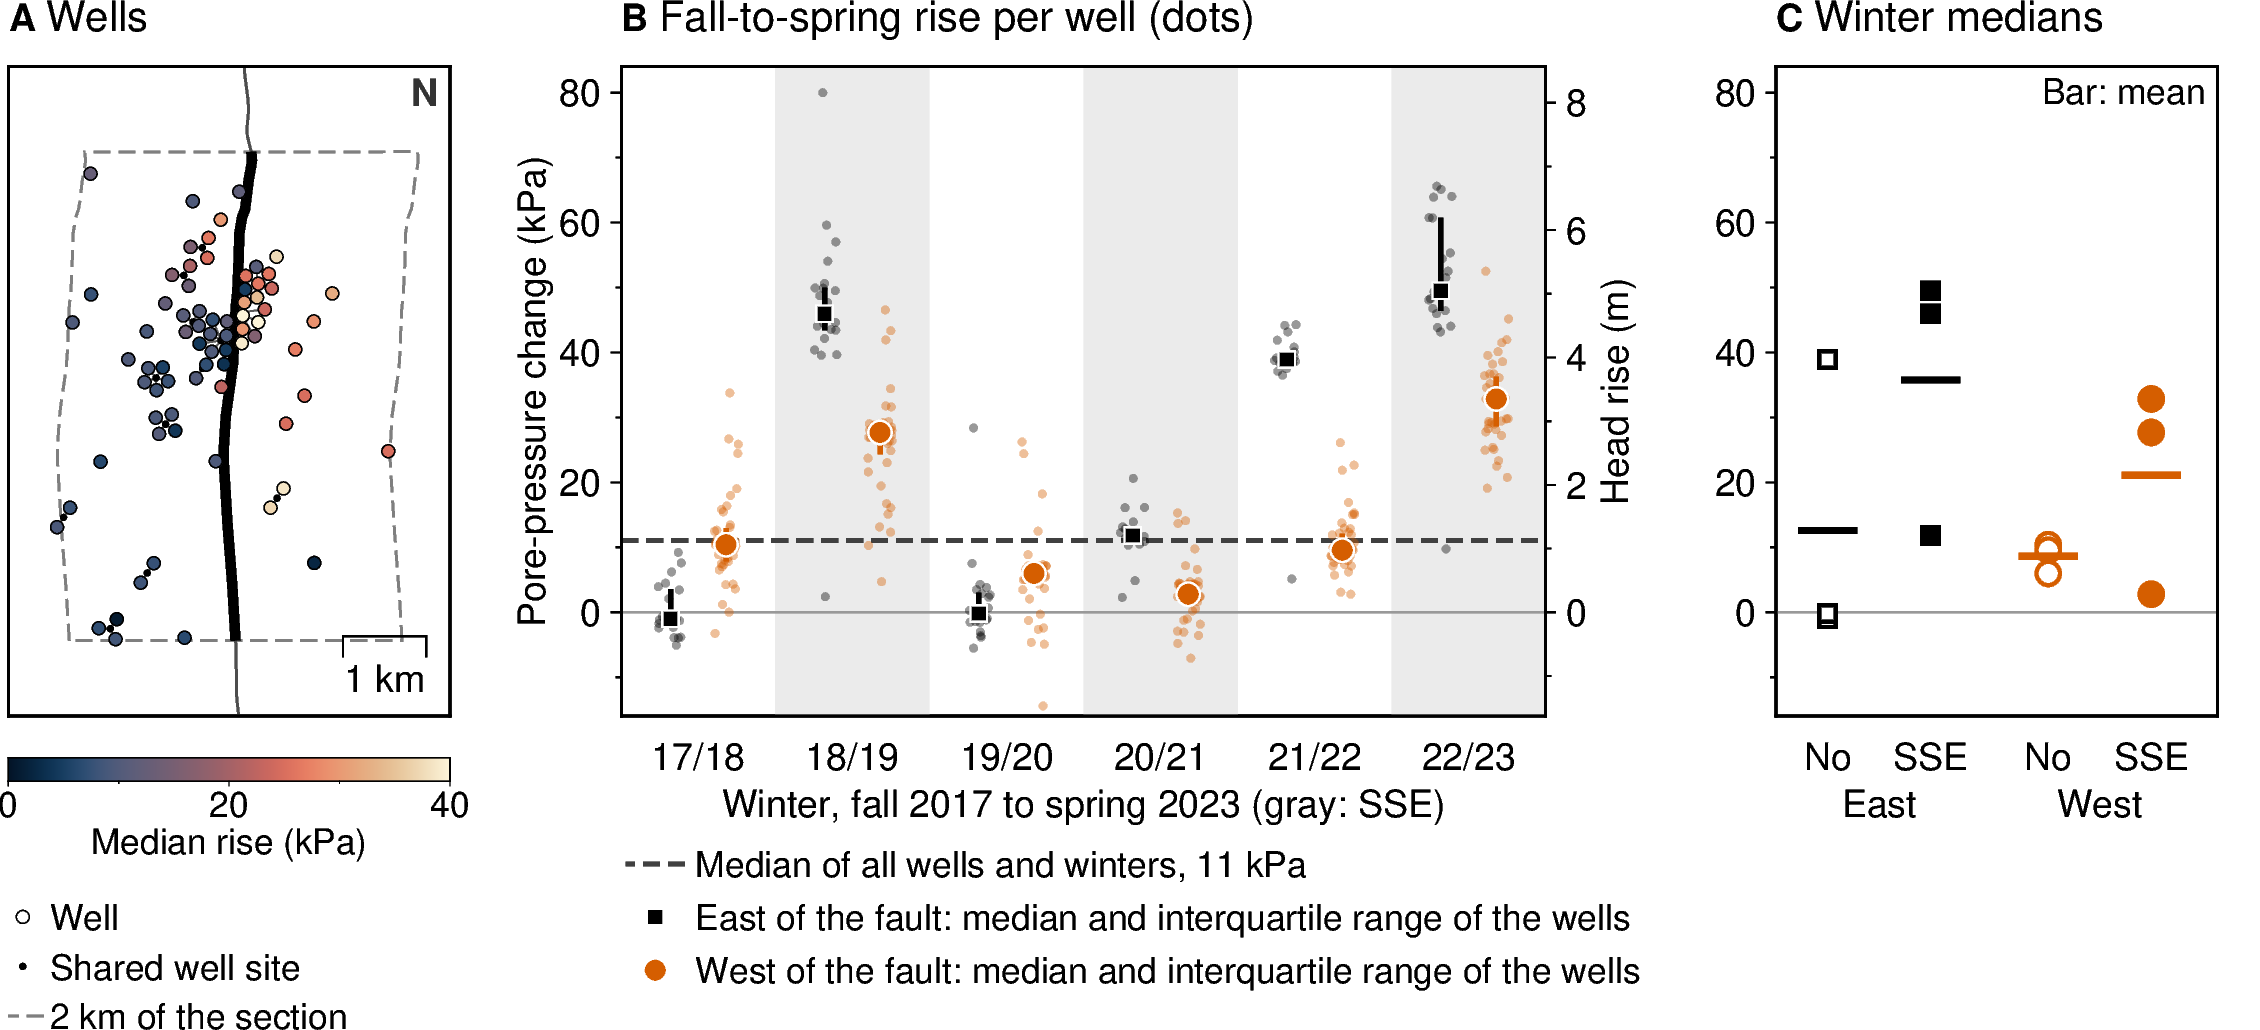

In [6]:
COL = {"east": "black", "west": "#D55E00"}; SYM = {"east": "s", "west": "c"}
d = R
wellmed = d.groupby("well").agg(kpa=("rise_kpa", "median"), side=("side", "first"), lat=("lat", "first"), lon=("lon", "first"))
lab = lambda letter, text: f"@%Helvetica-Bold%{letter}@%% @:10p:{text}@::"
F, FS = "9p,Helvetica", "8.5p,Helvetica"
T = trace
M_LAT, M_LON = gw.M_PER_DEG_LAT, gw.M_PER_DEG_LON
LAT0, LON0 = gw.PLSS_ORIGIN

STRIKE, KM_C, HALF_ALONG, HALF_ACROSS = 146.5, 0.5 * (section_km[0] + section_km[1]), 3.9, 2.65
c = T.iloc[int(np.argmin(np.abs(T.km - KM_C)))]
def offset(lat, lon, along_km, across_km):          # along strike (SE +) and across (NE +), km -> lon/lat
    a, x = np.radians(STRIKE), np.radians(STRIKE - 90)
    dn = along_km * np.cos(a) + across_km * np.cos(x); de = along_km * np.sin(a) + across_km * np.sin(x)
    return lon + de * 1000 / M_LON, lat + dn * 1000 / M_LAT
ll = offset(c.ft_lat, c.ft_lon, HALF_ALONG, -HALF_ACROSS); ur = offset(c.ft_lat, c.ft_lon, -HALF_ALONG, HALF_ACROSS)
region = f"{ll[0]:.5f}/{ll[1]:.5f}/{ur[0]:.5f}/{ur[1]:.5f}+r"
H = 5.5                                                                  # height of every panel (cm)
w0, h0 = utils.gmt_map_size([region], f"Oa{c.ft_lon}/{c.ft_lat}/{STRIKE - 90}/4c")
MAP_W = 4 * H / h0; CW = MAP_W                                           # C as wide as A
proj = f"Oa{c.ft_lon}/{c.ft_lat}/{STRIKE - 90}/{MAP_W:.3f}c"
sse_tr = T[(T.km >= section_km[0]) & (T.km <= section_km[1])]
CM_PER_KM = MAP_W / (2 * HALF_ACROSS)

# selection zone: the SSE section offset 2 km to either side
zx = [offset(la, lo_, 0, -max_dist_km) for la, lo_ in zip(sse_tr.ft_lat, sse_tr.ft_lon)]
ze = [offset(la, lo_, 0, max_dist_km) for la, lo_ in zip(sse_tr.ft_lat, sse_tr.ft_lon)]
zone = zx + ze[::-1] + [zx[0]]

# fan out wells that share a tract: start on a ring around the tract centre, then push apart overlapping symbols
wellmed["tract"] = wellmed.index.str[:9]
X = ((wellmed.lon - LON0) * M_LON / 1e3).to_numpy(); Y = ((wellmed.lat - LAT0) * M_LAT / 1e3).to_numpy()
px, py = X.copy(), Y.copy()
for t, idx in wellmed.groupby("tract").indices.items():
    n = len(idx)
    if n > 1:
        r0 = max(0.14, n * 0.18 / (2 * np.pi)); ang = np.radians(90 + 360 * np.arange(n) / n)
        px[idx] += r0 * np.cos(ang); py[idx] += r0 * np.sin(ang)
ax, ay = px.copy(), py.copy(); SYMW = 0.11; DMIN = SYMW / CM_PER_KM * 1.12      # symbol plus a gap, in km
tx = ((T.ft_lon - LON0) * M_LON / 1e3).to_numpy(); ty = ((T.ft_lat - LAT0) * M_LAT / 1e3).to_numpy()
ux, uy = np.sin(np.radians(STRIKE - 90)), np.cos(np.radians(STRIKE - 90))   # across-fault unit vector, NE positive
sgn = np.where(wellmed.side.to_numpy() == "east", 1.0, -1.0)
MARGIN = 0.6 * SYMW / CM_PER_KM                                              # keep symbols clear of the trace
def keep_side():
    for k in range(len(px)):
        i = int(np.argmin(np.hypot(tx - px[k], ty - py[k])))
        u = (px[k] - tx[i]) * ux + (py[k] - ty[i]) * uy
        if sgn[k] * u < MARGIN:                                              # on the wrong side or on the trace
            shift = sgn[k] * MARGIN - u; px[k] += shift * ux; py[k] += shift * uy
for _ in range(500):
    dx = px[:, None] - px[None, :]; dy = py[:, None] - py[None, :]; dd = np.hypot(dx, dy) + np.eye(len(px))
    push = np.clip(DMIN - dd, 0, None) / dd * 0.5; np.fill_diagonal(push, 0)
    px += (push * dx).sum(1) + 0.03 * (ax - px); py += (push * dy).sum(1) + 0.03 * (ay - py)
    keep_side()
wellmed["plon"] = LON0 + px * 1e3 / M_LON; wellmed["plat"] = LAT0 + py * 1e3 / M_LAT
moved = np.hypot(px - X, py - Y) > 0.05
print(f"{len(wellmed)} wells at {wellmed.tract.nunique()} tract positions; {moved.sum()} symbols offset from their tract")

yr = [-16, 84]                                                          # data range -14.4 to 80.0 kPa (asserted)
assert d.rise_kpa.min() > yr[0] and d.rise_kpa.max() < yr[1], "a rise outside the plotted range"
GAP1, GAP2 = 1.45, 1.95
BW = 19.0 - MAP_W - GAP1 - GAP2 - CW - 0.3
print(f"panel widths: A {MAP_W:.2f}, B {BW:.2f}, C {CW:.2f} cm; height {H} cm")

fig = pygmt.Figure()
with pygmt.config(FONT="10p,Helvetica", FONT_ANNOT_PRIMARY=F, FONT_LABEL=F, MAP_FRAME_TYPE="plain",
                  MAP_TICK_LENGTH_PRIMARY="0.08c", MAP_FRAME_PEN="0.6p", PS_PAGE_COLOR="white", MAP_LABEL_OFFSET="0.12c"):
    # A: map
    fig.basemap(region=region, projection=proj, frame=["lrtb"])
    fig.plot(x=[z[0] for z in zone], y=[z[1] for z in zone], pen="0.6p,gray50,4_2:0")
    fig.plot(x=T.ft_lon, y=T.ft_lat, pen="0.6p,gray30")
    fig.plot(x=sse_tr.ft_lon, y=sse_tr.ft_lat, pen="2.4p,black")
    for (w, r), mv in zip(wellmed.iterrows(), moved):
        if mv: fig.plot(x=[r.lon, r.plon], y=[r.lat, r.plat], pen="0.35p,gray35")
    cen = wellmed[moved].drop_duplicates("tract")
    fig.plot(x=cen.lon, y=cen.lat, style="c0.06c", fill="black")
    pygmt.makecpt(cmap="lipari", series=[0, 40, 1], continuous=True)
    for s in ("east", "west"):
        g = wellmed[wellmed.side == s]
        fig.plot(x=g.plon, y=g.plat, fill=g.kpa.clip(0, 40), cmap=True, style=f"c{SYMW}c", pen="0.25p,black")
    fig.text(position="TR", text="N", offset="-0.1c/-0.1c", font="9p,Helvetica-Bold,gray20")
    fig.basemap(region=region, projection=proj, frame=["lrtb"], map_scale="jBR+w1k+o0.2c/0.5c")
    fig.text(position="TL", text=lab("A", "Wells"), offset="0c/0.3c", no_clip=True, justify="BL")
    with pygmt.config(FONT_ANNOT_PRIMARY="17p", FONT_LABEL="17p"):     # GMT scales colour-bar text with bar thickness
        fig.colorbar(position=f"JBC+w{MAP_W:.2f}c/0.2c+h+o0c/0.35c", frame=["xa20f10+lMedian rise (kPa)"])
    fig.shift_origin(yshift="-2.75c")                                    # key under the colour bar
    fig.basemap(region=[0, MAP_W, 0, 1.2], projection=f"X{MAP_W:.3f}c/1.2c", frame="+n")
    fig.plot(x=[0.12], y=[1.05], style=f"c{SYMW}c", pen="0.25p,black", fill="white"); fig.text(x=0.35, y=1.05, text="Well", justify="ML", font=FS)
    fig.plot(x=[0.12], y=[0.63], style="c0.06c", fill="black"); fig.text(x=0.35, y=0.63, text="Shared well site", justify="ML", font=FS)
    fig.plot(x=[0.12], y=[0.21], style="-0.35c", pen="0.6p,gray50,4_2:0"); fig.text(x=0.35, y=0.21, text=f"{max_dist_km:g} km of the section", justify="ML", font=FS)
    fig.shift_origin(yshift="2.75c")

    # B: per winter
    fig.shift_origin(xshift=f"{MAP_W + GAP1:.3f}c")
    xr = [-0.5, 5.5]; RB = dict(region=xr + yr, projection=f"X{BW:.3f}c/{H}c")
    fig.basemap(frame=["Wsn", "ya20f10+lPore-pressure change (kPa)"], **RB)
    for i, w in enumerate(winters):
        if d.loc[d.winter == w, "sse"].iloc[0]:
            fig.plot(x=[i - 0.5, i + 0.5, i + 0.5, i - 0.5], y=[yr[0], yr[0], yr[1], yr[1]], fill="gray92", close=True)
    fig.plot(x=xr, y=[0, 0], pen="0.4p,gray60")
    pooled = np.percentile(d["rise_kpa"], [25, 50, 75])
    fig.plot(x=xr, y=[pooled[1]] * 2, pen="1p,gray25,4_2:0")
    rng = np.random.default_rng(0)                                        # horizontal jitter of the dots only
    for i, w in enumerate(winters):
        for s, off in (("east", -0.18), ("west", 0.18)):
            v = d.loc[(d.winter == w) & (d.side == s), "rise_kpa"].to_numpy()
            fig.plot(x=i + off + rng.uniform(-0.08, 0.08, v.size), y=v, style="c0.07c", fill=COL[s], transparency=60)
            q1, med, q3 = np.percentile(v, [25, 50, 75])
            fig.plot(x=[i + off] * 2, y=[q1, q3], pen=f"1.2p,{COL[s]}")
            fig.plot(x=[i + off], y=[med], style=f"{SYM[s]}0.2c", fill=COL[s], pen="0.4p,white")
        fig.text(x=i, y=yr[0], text=w[2:4] + "/" + w[-2:], offset="0c/-0.22c", justify="TC", font=F, no_clip=True)
    fig.text(x=2.5, y=yr[0], text=f"Winter, fall {winters[0][:4]} to spring 20{winters[-1][-2:]} (gray: SSE)", offset="0c/-0.62c",
             justify="TC", font=F, no_clip=True)
    yk = lambda cm: yr[0] - cm * (yr[1] - yr[0]) / H                    # data y at cm below the frame
    fig.plot(x=[-0.28], y=[yk(1.25)], style="-0.5c", pen="1p,gray25,4_2:0", no_clip=True)
    fig.text(x=-0.02, y=yk(1.25), text=f"Median of all wells and winters, {pooled[1]:.0f} kPa", justify="ML", font=FS, no_clip=True)
    for cm, s_, txt in ((1.7, "east", "East of the fault"), (2.15, "west", "West of the fault")):
        fig.plot(x=[-0.28], y=[yk(cm)], style=f"{SYM[s_]}0.2c", fill=COL[s_], pen="0.4p,white", no_clip=True)
        fig.text(x=-0.02, y=yk(cm), text=txt + ": median and interquartile range of the wells", justify="ML", font=FS, no_clip=True)
    fig.basemap(region=xr + [yr[0] / gw.KPA_PER_M, yr[1] / gw.KPA_PER_M], projection=f"X{BW:.3f}c/{H}c",
                frame=["E", "ya2f1+lHead rise (m)"])
    fig.basemap(frame=["wsne"], **RB)                                     # redraw the frame over the shading
    fig.text(position="TL", text=lab("B", "Fall-to-spring rise per well (dots)"), offset="0c/0.3c", no_clip=True,
             justify="BL", **RB)

    # C: winter medians with and without an SSE
    fig.shift_origin(xshift=f"{BW + GAP2:.3f}c")
    cr = [-0.7, 5.3]; RC = dict(region=cr + yr, projection=f"X{CW:.3f}c/{H}c")
    fig.basemap(frame=["Wsn", "ya20f10"], **RC)
    fig.plot(x=cr, y=[0, 0], pen="0.4p,gray60")
    for j, s in enumerate(("east", "west")):
        for k, flag in enumerate((False, True)):
            meds = [np.median(d.loc[(d.winter == w) & (d.side == s), "rise_kpa"]) for w in winters
                    if d.loc[d.winter == w, "sse"].iloc[0] == flag]
            x = j * 3.0 + k * 1.4
            fig.plot(x=[x] * len(meds), y=meds, style=f"{SYM[s]}0.2c", pen=f"0.9p,{COL[s]}", fill=COL[s] if flag else "white")
            fig.plot(x=[x - 0.4, x + 0.4], y=[np.mean(meds)] * 2, pen=f"1.6p,{COL[s]}")
            fig.text(x=x, y=yr[0], text="SSE" if flag else "No", offset="0c/-0.22c", justify="TC", font=F, no_clip=True)
        fig.text(x=j * 3.0 + 0.7, y=yr[0], text="East" if s == "east" else "West", offset="0c/-0.62c", justify="TC",
                 font=F, no_clip=True)
    fig.text(position="TR", text="Bar: mean", offset="-0.1c/-0.1c", font=FS, justify="TR")
    fig.basemap(frame=["wsne"], **RC)                                     # full frame, drawn last
    fig.plot(x=[cr[1] + 0.35 * (cr[1] - cr[0]) / CW], y=[0], style="c0.01c", fill="white", pen="white", no_clip=True)  # 0.35 cm right margin
    fig.text(position="TL", text=lab("C", "Winter medians"), offset="0c/0.3c", no_clip=True, justify="BL")
f_fig = os.path.join(fig_dir, f"figS_groundwater_winter_rise_{max_dist_km:g}km.png")
for ext in ("png", "pdf"):
    fig.savefig(f_fig.replace(".png", f".{ext}"), dpi=300)
print("Saved figure to:", f_fig)
fig.show(width=900)

## 7. Registry: the stats sidecar `16_groundwater_head_stats.txt` and the `16_*` numbers

In [7]:
lines = [f"public ACWD GWMR reports read: {', '.join(str(y) for y in files)} (2016 and 2024 not found)",
         check.to_string(index=False),
         f"SSE section {section_km} km, peak-slip zone {peak_km} km; wells within {max_dist_km:g} km of the trace beside the section",
         f"{n_wells} wells ({n_east} east, {n_west} west), {len(R)} well-winters, winters {winters[0]} to {winters[-1]}; "
         f"InSAR SSE water years {sse_water_years}",
         "per winter (n, median rise in m):", per_winter.round(3).to_string(),
         "winter medians (kPa):", med_kpa.round(2).to_string(),
         f"mean of the winter medians, SSE / other winters: east {group['east']['sse_kpa']:.2f} / {group['east']['non_kpa']:.2f} kPa, "
         f"west {group['west']['sse_kpa']:.2f} / {group['west']['non_kpa']:.2f} kPa; overlap {overlap}",
         f"all wells and winters: median {q_m[1]:.3f} m ({q_kpa[1]:.2f} kPa), IQR {q_m[0]:.3f}-{q_m[2]:.3f} m "
         f"({q_kpa[0]:.2f}-{q_kpa[2]:.2f} kPa); strength change at mu' {friction}: {strength[1]:.2f} ({strength[0]:.2f}-{strength[2]:.2f}) kPa",
         f"smallest west winter median {smallest_west_wy}: {smallest_west_kpa:.2f} kPa",
         "selection sensitivity:", sens.round(2).to_string(index=False)]
sidecar = REG.sidecar(notebook, lines)
cell = "winter-rise"
REG.register("16_n_reports", len(files), "count", 0, where="M9", cell="reports", sidecar=sidecar)
REG.register("16_n_wells", n_wells, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_wells_east", n_east, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_wells_west", n_west, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_well_winters", len(R), "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_winters", len(winters), "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_sse_winters", n_sse_winters, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_n_other_winters", n_other_winters, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_winter_first", winters[0], "date", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_winter_last", winters[-1], "date", 0, where="M9", cell=cell, sidecar=sidecar)
for side in ("east", "west"):
    for grp, name in (("sse_kpa", "sse"), ("non_kpa", "other")):
        v = group[side][grp]
        REG.register(f"16_{name}_winters_{side}_kpa", v, "kPa", 1, where="M9", cell=cell, sidecar=sidecar)
        REG.register(f"16_{name}_winters_{side}_m", v / gw.KPA_PER_M, "m", 3, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_median_m", q_m[1], "m", 2, where="P3, M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_iqr_lo_m", q_m[0], "m", 2, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_iqr_hi_m", q_m[2], "m", 2, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_median_kpa", q_kpa[1], "kPa", 1, where="P3, M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_iqr_lo_kpa", q_kpa[0], "kPa", 1, where="P3, M9", cell=cell, sidecar=sidecar)
REG.register("16_rise_iqr_hi_kpa", q_kpa[2], "kPa", 1, where="P3, M9", cell=cell, sidecar=sidecar)
REG.register("16_friction", friction, "1", 1, where="Discussion", cell=cell, sidecar=sidecar)
REG.register("16_strength_change_kpa", strength[1], "kPa", 1, where="Discussion", cell=cell, sidecar=sidecar)
REG.register("16_strength_change_lo_kpa", strength[0], "kPa", 1, where="Discussion", cell=cell, sidecar=sidecar)
REG.register("16_strength_change_hi_kpa", strength[2], "kPa", 1, where="Discussion", cell=cell, sidecar=sidecar)
REG.register("16_smallest_west_water_year", smallest_west_wy, "count", 0, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_smallest_west_kpa", smallest_west_kpa, "kPa", 1, where="M9", cell=cell, sidecar=sidecar)
REG.register("16_selection_dist_median_lo_kpa", dist_lo, "kPa", 1, where="M9", cell="selection", sidecar=sidecar)
REG.register("16_selection_dist_median_hi_kpa", dist_hi, "kPa", 1, where="M9", cell="selection", sidecar=sidecar)
REG.register("16_selection_all_median_lo_kpa", sens.median_kpa.min(), "kPa", 1, where="M9", cell="selection", sidecar=sidecar)
REG.register("16_selection_all_median_hi_kpa", sens.median_kpa.max(), "kPa", 1, where="M9", cell="selection", sidecar=sidecar)
REG.render()

Saved stats to: /private/tmp/claude-502/-Users-dlindsay/0fdd737d-78e2-4e46-9e93-b9a364351a33/scratchpad/nb16_root/outputs/16_groundwater_head/16_groundwater_head_stats.txt
  registered 16_n_reports = 9 count  -> M9
  registered 16_n_wells = 73 count  -> M9
  registered 16_n_wells_east = 24 count  -> M9
  registered 16_n_wells_west = 49 count  -> M9
  registered 16_n_well_winters = 385 count  -> M9
  registered 16_n_winters = 6 count  -> M9
  registered 16_n_sse_winters = 3 count  -> M9
  registered 16_n_other_winters = 3 count  -> M9


  registered 16_winter_first = 2017/18 date  -> M9
  registered 16_winter_last = 2022/23 date  -> M9
  registered 16_sse_winters_east_kpa = 35.8 kPa  -> M9
  registered 16_sse_winters_east_m = 3.647 m  -> M9
  registered 16_other_winters_east_kpa = 12.6 kPa  -> M9
  registered 16_other_winters_east_m = 1.283 m  -> M9
  registered 16_sse_winters_west_kpa = 21.1 kPa  -> M9
  registered 16_sse_winters_west_m = 2.151 m  -> M9
  registered 16_other_winters_west_kpa = 8.6 kPa  -> M9


  registered 16_other_winters_west_m = 0.880 m  -> M9
  registered 16_rise_median_m = 1.13 m  -> P3, M9
  registered 16_rise_iqr_lo_m = 0.48 m  -> M9
  registered 16_rise_iqr_hi_m = 2.98 m  -> M9
  registered 16_rise_median_kpa = 11.1 kPa  -> P3, M9
  registered 16_rise_iqr_lo_kpa = 4.7 kPa  -> P3, M9
  registered 16_rise_iqr_hi_kpa = 29.2 kPa  -> P3, M9
  registered 16_friction = 0.4 1  -> Discussion
  registered 16_strength_change_kpa = 4.4 kPa  -> Discussion


  registered 16_strength_change_lo_kpa = 1.9 kPa  -> Discussion
  registered 16_strength_change_hi_kpa = 11.7 kPa  -> Discussion
  registered 16_smallest_west_water_year = 2021 count  -> M9
  registered 16_smallest_west_kpa = 2.8 kPa  -> M9
  registered 16_selection_dist_median_lo_kpa = 10.4 kPa  -> M9
  registered 16_selection_dist_median_hi_kpa = 12.3 kPa  -> M9
  registered 16_selection_all_median_lo_kpa = 10.3 kPa  -> M9
  registered 16_selection_all_median_hi_kpa = 12.3 kPa  -> M9
Wrote the numbers to: /private/tmp/claude-502/-Users-dlindsay/0fdd737d-78e2-4e46-9e93-b9a364351a33/scratchpad/nb16_root/outputs/paper_numbers.md


'/private/tmp/claude-502/-Users-dlindsay/0fdd737d-78e2-4e46-9e93-b9a364351a33/scratchpad/nb16_root/outputs/paper_numbers.md'